# 01 – Oldman River Dam: coregistered SLC stack and geometry with ISCE2 (topsStack)

**What this notebook makes**
- `slcStack.h5`: the **coregistered SLCs** (complex, full resolution) for every date. They are cropped to the dam area and all sit on the reference grid of **21 May 2017**.
- `geometryRadar.h5`: **height, latitude, longitude, incidence angle, azimuth angle, shadow mask and slant range** on the same grid.

Both files end up in `~/oldman_isce2/stack_<MODE>/miaplpy/inputs/`.

**Why not HyP3?** HyP3's ISCE2 jobs (`INSAR_ISCE_BURST`, `INSAR_ISCE_MULTI_BURST`) only deliver finished interferograms as GeoTIFFs. They give no coregistered SLCs and no geometry `.h5`. So this notebook runs the same ISCE2 software (topsStack, `-W slc` workflow) itself on OpenSARlab. It downloads **only the 2 bursts** that cover the dam (`071_151134_IW2`, `071_151135_IW2`) from ASF, not whole scenes.

**Data:** Sentinel-1B, descending track 71, IW2, VV. The 144 dates run from 26 Feb 2017 to 14 Dec 2021, with reference 21 May 2017 (the same as in SNAP).

**Steps:**

| Step | What happens | Time (rough) |
|---|---|---|
| 1–2 | settings, checks, Earthdata login | 1 min |
| 3–4 | find the bursts, download them, rebuild SAFE files | TEST ~5 min, FULL 1–3 h |
| 5–6 | precise orbits, Copernicus DEM | 5–10 min |
| 7–8 | ISCE2 topsStack: coregistration with ESD, merge | TEST 30–60 min, FULL 12–24 h |
| 9 | ESD shifts table | 1 min |
| 10 | `slcStack.h5` + `geometryRadar.h5` | TEST 2 min, FULL 15–30 min |

The times are estimates. The notebook writes the real duration of every step to `logs/STEP_TIMES.txt`, so after the TEST you can work out the FULL time.

**How to use it**
1. Run **00_Setup** once. Then choose the kernel **`oldman_isce2`** for this notebook.
2. Leave `MODE = 'TEST'` (3 dates) and run all cells. Check the result at the end.
3. Change to `MODE = 'FULL'` and run all cells again. Files that are already downloaded are reused.

**Keep this browser tab open while it runs.** OpenSARlab says the server stays on while a notebook is open in an active tab, and may shut down after about an hour of inactivity. If it stops anyway, run the cells again: every step skips the work that is already finished.

## 1. Settings: the only cell you normally change

In [21]:
import os, sys, json, time, shutil, subprocess, logging, datetime as dt
from pathlib import Path

MODE = 'FULL'          # 'TEST' = 3 dates (do this first), 'FULL' = all 144 dates

BASE      = Path.home() / 'oldman_isce2'   # everything is saved under this folder
REF_DATE  = '20170521'                    # reference date, the same as in SNAP
TEST_DATES = ['20170521', '20170602', '20170614']   # three consecutive 12-day dates
BURST_IDS = ['071_151134_IW2', '071_151135_IW2']    # the dam is in 151134; 151135 adds the overlap ESD needs
AOI_LALO  = '49.53:49.60,-113.96:-113.83'           # S:N,W:E - same AOI as the SNAP run
DEM_BBOX  = (-115.0, 49.2, -113.2, 50.0)            # W S E N - covers both bursts with margin
N_PROC    = os.cpu_count() or 4                     # parallel ISCE jobs

# the 144 Sentinel-1B scenes (date: original scene name, used to fetch the precise orbit)
SCENES = {
    '20170226': 'S1B_IW_SLC__1SSV_20170226T134713_20170226T134740_004472_007C8A_770B',
    '20170310': 'S1B_IW_SLC__1SSV_20170310T134713_20170310T134740_004647_0081A6_14A4',
    '20170322': 'S1B_IW_SLC__1SSV_20170322T134713_20170322T134740_004822_0086C4_FF2D',
    '20170403': 'S1B_IW_SLC__1SSV_20170403T134713_20170403T134740_004997_008BD3_B7A7',
    '20170415': 'S1B_IW_SLC__1SSV_20170415T134714_20170415T134741_005172_0090D2_8FD5',
    '20170427': 'S1B_IW_SLC__1SSV_20170427T134714_20170427T134741_005347_0095F4_332E',
    '20170509': 'S1B_IW_SLC__1SSV_20170509T134715_20170509T134742_005522_009ACC_3D08',
    '20170521': 'S1B_IW_SLC__1SDV_20170521T134716_20170521T134743_005697_009FB1_2A7A',
    '20170602': 'S1B_IW_SLC__1SDV_20170602T134716_20170602T134743_005872_00A4BE_0049',
    '20170614': 'S1B_IW_SLC__1SDV_20170614T134717_20170614T134744_006047_00A9E4_C575',
    '20170626': 'S1B_IW_SLC__1SDV_20170626T134718_20170626T134745_006222_00AEFA_DD65',
    '20170708': 'S1B_IW_SLC__1SDV_20170708T134718_20170708T134745_006397_00B3EE_7DD3',
    '20170720': 'S1B_IW_SLC__1SDV_20170720T134719_20170720T134746_006572_00B8ED_AC28',
    '20170801': 'S1B_IW_SLC__1SDV_20170801T134720_20170801T134747_006747_00BDF4_B6FC',
    '20170813': 'S1B_IW_SLC__1SDV_20170813T134720_20170813T134747_006922_00C30D_E2D7',
    '20170825': 'S1B_IW_SLC__1SDV_20170825T134721_20170825T134748_007097_00C81D_560B',
    '20170906': 'S1B_IW_SLC__1SDV_20170906T134721_20170906T134748_007272_00CD33_80F4',
    '20170918': 'S1B_IW_SLC__1SDV_20170918T134722_20170918T134749_007447_00D256_9ABD',
    '20170930': 'S1B_IW_SLC__1SDV_20170930T134722_20170930T134749_007622_00D75D_6063',
    '20171012': 'S1B_IW_SLC__1SDV_20171012T134722_20171012T134749_007797_00DC5A_955D',
    '20171024': 'S1B_IW_SLC__1SDV_20171024T134723_20171024T134750_007972_00E15A_84EB',
    '20171117': 'S1B_IW_SLC__1SDV_20171117T134722_20171117T134749_008322_00EBA6_FE58',
    '20171129': 'S1B_IW_SLC__1SDV_20171129T134722_20171129T134749_008497_00F111_FD34',
    '20171211': 'S1B_IW_SLC__1SDV_20171211T134722_20171211T134749_008672_00F69F_E9AA',
    '20171223': 'S1B_IW_SLC__1SDV_20171223T134721_20171223T134748_008847_00FC31_D23F',
    '20180104': 'S1B_IW_SLC__1SDV_20180104T134720_20180104T134747_009022_0101E0_A4AE',
    '20180116': 'S1B_IW_SLC__1SDV_20180116T134720_20180116T134747_009197_010792_AD9D',
    '20180128': 'S1B_IW_SLC__1SDV_20180128T134720_20180128T134747_009372_010D4B_9883',
    '20180209': 'S1B_IW_SLC__1SDV_20180209T134719_20180209T134746_009547_01130E_43CA',
    '20180221': 'S1B_IW_SLC__1SDV_20180221T134719_20180221T134746_009722_0118CC_3A20',
    '20180305': 'S1B_IW_SLC__1SDV_20180305T134719_20180305T134746_009897_011EA2_667B',
    '20180317': 'S1B_IW_SLC__1SDV_20180317T134719_20180317T134746_010072_012466_A237',
    '20180329': 'S1B_IW_SLC__1SDV_20180329T134720_20180329T134747_010247_012A10_5575',
    '20180410': 'S1B_IW_SLC__1SDV_20180410T134720_20180410T134747_010422_012FC2_87B8',
    '20180422': 'S1B_IW_SLC__1SDV_20180422T134720_20180422T134747_010597_013557_44B5',
    '20180504': 'S1B_IW_SLC__1SDV_20180504T134721_20180504T134748_010772_013AFA_A9DD',
    '20180516': 'S1B_IW_SLC__1SDV_20180516T134722_20180516T134749_010947_0140A0_B288',
    '20180528': 'S1B_IW_SLC__1SDV_20180528T134722_20180528T134749_011122_014655_3C7E',
    '20180609': 'S1B_IW_SLC__1SDV_20180609T134723_20180609T134750_011297_014BDB_10E6',
    '20180621': 'S1B_IW_SLC__1SDV_20180621T134724_20180621T134751_011472_01513E_F1C2',
    '20180703': 'S1B_IW_SLC__1SDV_20180703T134725_20180703T134752_011647_0156B5_D16D',
    '20180715': 'S1B_IW_SLC__1SDV_20180715T134725_20180715T134752_011822_015C19_73AB',
    '20180727': 'S1B_IW_SLC__1SDV_20180727T134726_20180727T134753_011997_016162_C411',
    '20180808': 'S1B_IW_SLC__1SDV_20180808T134727_20180808T134754_012172_0166B7_8D96',
    '20180820': 'S1B_IW_SLC__1SDV_20180820T134728_20180820T134755_012347_016C2C_4EA8',
    '20180901': 'S1B_IW_SLC__1SDV_20180901T134728_20180901T134755_012522_017194_4313',
    '20180913': 'S1B_IW_SLC__1SDV_20180913T134728_20180913T134755_012697_0176EB_7D80',
    '20180925': 'S1B_IW_SLC__1SDV_20180925T134729_20180925T134756_012872_017C51_249A',
    '20181007': 'S1B_IW_SLC__1SDV_20181007T134729_20181007T134756_013047_0181A7_667F',
    '20181019': 'S1B_IW_SLC__1SDV_20181019T134729_20181019T134756_013222_01870C_9E90',
    '20181031': 'S1B_IW_SLC__1SDV_20181031T134729_20181031T134756_013397_018C8B_301C',
    '20181112': 'S1B_IW_SLC__1SDV_20181112T134729_20181112T134756_013572_0191FB_42A3',
    '20181124': 'S1B_IW_SLC__1SDV_20181124T134729_20181124T134756_013747_019788_39C2',
    '20181206': 'S1B_IW_SLC__1SDV_20181206T134728_20181206T134755_013922_019D2F_53CE',
    '20181218': 'S1B_IW_SLC__1SDV_20181218T134728_20181218T134755_014097_01A2E9_A69F',
    '20181230': 'S1B_IW_SLC__1SDV_20181230T134728_20181230T134754_014272_01A8BF_2C7C',
    '20190111': 'S1B_IW_SLC__1SDV_20190111T134727_20190111T134754_014447_01AE65_0C4F',
    '20190123': 'S1B_IW_SLC__1SDV_20190123T134727_20190123T134754_014622_01B400_C02C',
    '20190204': 'S1B_IW_SLC__1SDV_20190204T134726_20190204T134753_014797_01B9B4_353F',
    '20190216': 'S1B_IW_SLC__1SDV_20190216T134726_20190216T134753_014972_01BF6D_69DE',
    '20190312': 'S1B_IW_SLC__1SDV_20190312T134726_20190312T134753_015322_01CAEA_8BFE',
    '20190324': 'S1B_IW_SLC__1SDV_20190324T134726_20190324T134753_015497_01D094_BA77',
    '20190405': 'S1B_IW_SLC__1SDV_20190405T134726_20190405T134753_015672_01D65F_C351',
    '20190417': 'S1B_IW_SLC__1SDV_20190417T134727_20190417T134754_015847_01DC2E_79EC',
    '20190429': 'S1B_IW_SLC__1SDV_20190429T134727_20190429T134754_016022_01E1FF_17CA',
    '20190511': 'S1B_IW_SLC__1SDV_20190511T134728_20190511T134755_016197_01E7B1_C4BD',
    '20190523': 'S1B_IW_SLC__1SDV_20190523T134729_20190523T134756_016372_01ED1F_4E2D',
    '20190604': 'S1B_IW_SLC__1SDV_20190604T134729_20190604T134756_016547_01F26A_9A85',
    '20190616': 'S1B_IW_SLC__1SDV_20190616T134730_20190616T134757_016722_01F799_DB15',
    '20190628': 'S1B_IW_SLC__1SDV_20190628T134730_20190628T134757_016897_01FCC3_FAB0',
    '20190710': 'S1B_IW_SLC__1SDV_20190710T134731_20190710T134758_017072_0201F1_90FB',
    '20190722': 'S1B_IW_SLC__1SDV_20190722T134732_20190722T134759_017247_020707_E848',
    '20190803': 'S1B_IW_SLC__1SDV_20190803T134733_20190803T134800_017422_020C47_5CB7',
    '20190815': 'S1B_IW_SLC__1SDV_20190815T134733_20190815T134800_017597_0211A8_3EDE',
    '20190827': 'S1B_IW_SLC__1SDV_20190827T134734_20190827T134801_017772_021723_5A4B',
    '20190908': 'S1B_IW_SLC__1SDV_20190908T134735_20190908T134802_017947_021C8F_531B',
    '20190920': 'S1B_IW_SLC__1SDV_20190920T134735_20190920T134802_018122_0221FD_7921',
    '20191002': 'S1B_IW_SLC__1SDV_20191002T134736_20191002T134802_018297_02276F_9D0E',
    '20191014': 'S1B_IW_SLC__1SDV_20191014T134736_20191014T134803_018472_022CDD_BD60',
    '20191026': 'S1B_IW_SLC__1SDV_20191026T134736_20191026T134803_018647_02323A_DF66',
    '20191107': 'S1B_IW_SLC__1SDV_20191107T134735_20191107T134802_018822_0237DB_1D54',
    '20191119': 'S1B_IW_SLC__1SDV_20191119T134735_20191119T134802_018997_023D86_7757',
    '20191201': 'S1B_IW_SLC__1SDV_20191201T134735_20191201T134802_019172_024314_9C6F',
    '20191213': 'S1B_IW_SLC__1SDV_20191213T134735_20191213T134802_019347_0248A6_F535',
    '20191225': 'S1B_IW_SLC__1SDV_20191225T134734_20191225T134801_019522_024E39_5B51',
    '20200106': 'S1B_IW_SLC__1SDV_20200106T134733_20200106T134800_019697_0253C8_08CA',
    '20200118': 'S1B_IW_SLC__1SDV_20200118T134733_20200118T134800_019872_02595A_C36A',
    '20200130': 'S1B_IW_SLC__1SDV_20200130T134733_20200130T134800_020047_025EF3_94CA',
    '20200211': 'S1B_IW_SLC__1SDV_20200211T134732_20200211T134759_020222_0264A7_75A4',
    '20200223': 'S1B_IW_SLC__1SDV_20200223T134732_20200223T134759_020397_026A46_AA39',
    '20200306': 'S1B_IW_SLC__1SDV_20200306T134732_20200306T134759_020572_026FD3_8E32',
    '20200318': 'S1B_IW_SLC__1SDV_20200318T134732_20200318T134759_020747_027566_6A47',
    '20200330': 'S1B_IW_SLC__1SDV_20200330T134732_20200330T134759_020922_027AE8_7867',
    '20200411': 'S1B_IW_SLC__1SDV_20200411T134733_20200411T134800_021097_028078_0B6A',
    '20200423': 'S1B_IW_SLC__1SDV_20200423T134733_20200423T134800_021272_0285FC_8825',
    '20200505': 'S1B_IW_SLC__1SDV_20200505T134734_20200505T134801_021447_028B8A_9DB3',
    '20200517': 'S1B_IW_SLC__1SDV_20200517T134734_20200517T134801_021622_0290C9_161C',
    '20200529': 'S1B_IW_SLC__1SDV_20200529T134735_20200529T134802_021797_0295FB_6869',
    '20200610': 'S1B_IW_SLC__1SDV_20200610T134736_20200610T134803_021972_029B38_35DA',
    '20200622': 'S1B_IW_SLC__1SDV_20200622T134737_20200622T134804_022147_02A08E_5AF7',
    '20200704': 'S1B_IW_SLC__1SDV_20200704T134737_20200704T134804_022322_02A5E5_B17F',
    '20200716': 'S1B_IW_SLC__1SDV_20200716T134738_20200716T134805_022497_02AB31_5A8C',
    '20200728': 'S1B_IW_SLC__1SDV_20200728T134739_20200728T134806_022672_02B089_5730',
    '20200809': 'S1B_IW_SLC__1SDV_20200809T134740_20200809T134807_022847_02B5E7_19DD',
    '20200821': 'S1B_IW_SLC__1SDV_20200821T134740_20200821T134807_023022_02BB5D_415B',
    '20200902': 'S1B_IW_SLC__1SDV_20200902T134741_20200902T134808_023197_02C0D1_6392',
    '20200914': 'S1B_IW_SLC__1SDV_20200914T134741_20200914T134808_023372_02C64E_B11D',
    '20200926': 'S1B_IW_SLC__1SDV_20200926T134742_20200926T134809_023547_02CBCA_41C1',
    '20201008': 'S1B_IW_SLC__1SDV_20201008T134742_20201008T134809_023722_02D141_D237',
    '20201020': 'S1B_IW_SLC__1SDV_20201020T134742_20201020T134809_023897_02D6B0_A772',
    '20201101': 'S1B_IW_SLC__1SDV_20201101T134742_20201101T134809_024072_02DC2A_2B03',
    '20201113': 'S1B_IW_SLC__1SDV_20201113T134742_20201113T134809_024247_02E19A_EF44',
    '20201125': 'S1B_IW_SLC__1SDV_20201125T134741_20201125T134808_024422_02E722_A065',
    '20201207': 'S1B_IW_SLC__1SDV_20201207T134741_20201207T134808_024597_02ECBE_AA55',
    '20201219': 'S1B_IW_SLC__1SDV_20201219T134740_20201219T134807_024772_02F267_DD3C',
    '20201231': 'S1B_IW_SLC__1SDV_20201231T134740_20201231T134807_024947_02F80A_4D6E',
    '20210112': 'S1B_IW_SLC__1SDV_20210112T134739_20210112T134806_025122_02FDAB_54AE',
    '20210124': 'S1B_IW_SLC__1SDV_20210124T134739_20210124T134806_025297_03033A_F2CD',
    '20210217': 'S1B_IW_SLC__1SDV_20210217T134738_20210217T134805_025647_030E9D_8C91',
    '20210301': 'S1B_IW_SLC__1SDV_20210301T134738_20210301T134805_025822_031451_C7CB',
    '20210313': 'S1B_IW_SLC__1SDV_20210313T134738_20210313T134805_025997_0319FF_6278',
    '20210325': 'S1B_IW_SLC__1SDV_20210325T134738_20210325T134805_026172_031F8F_1440',
    '20210406': 'S1B_IW_SLC__1SDV_20210406T134739_20210406T134806_026347_03252B_4936',
    '20210418': 'S1B_IW_SLC__1SDV_20210418T134739_20210418T134806_026522_032ABD_68BF',
    '20210430': 'S1B_IW_SLC__1SDV_20210430T134739_20210430T134806_026697_033058_8660',
    '20210512': 'S1B_IW_SLC__1SDV_20210512T134740_20210512T134807_026872_0335E3_B631',
    '20210524': 'S1B_IW_SLC__1SDV_20210524T134741_20210524T134808_027047_033B3F_994C',
    '20210605': 'S1B_IW_SLC__1SDV_20210605T134742_20210605T134809_027222_034077_EAFF',
    '20210617': 'S1B_IW_SLC__1SDV_20210617T134742_20210617T134809_027397_0345B2_FACF',
    '20210629': 'S1B_IW_SLC__1SDV_20210629T134743_20210629T134810_027572_034A9E_145B',
    '20210711': 'S1B_IW_SLC__1SDV_20210711T134744_20210711T134811_027747_034FBB_9739',
    '20210723': 'S1B_IW_SLC__1SDV_20210723T134744_20210723T134811_027922_0354EB_EAB2',
    '20210804': 'S1B_IW_SLC__1SDV_20210804T134745_20210804T134812_028097_035A18_EFA5',
    '20210816': 'S1B_IW_SLC__1SDV_20210816T134746_20210816T134813_028272_035F89_4A6A',
    '20210828': 'S1B_IW_SLC__1SDV_20210828T134746_20210828T134813_028447_0364FD_71C8',
    '20210909': 'S1B_IW_SLC__1SDV_20210909T134747_20210909T134814_028622_036A77_24D5',
    '20210921': 'S1B_IW_SLC__1SDV_20210921T134747_20210921T134814_028797_036FD3_B7A1',
    '20211003': 'S1B_IW_SLC__1SDV_20211003T134748_20211003T134815_028972_03751C_2C02',
    '20211015': 'S1B_IW_SLC__1SDV_20211015T134748_20211015T134815_029147_037A79_92C0',
    '20211027': 'S1B_IW_SLC__1SDV_20211027T134748_20211027T134815_029322_037FE8_3191',
    '20211108': 'S1B_IW_SLC__1SDV_20211108T134747_20211108T134814_029497_03853D_EDA5',
    '20211120': 'S1B_IW_SLC__1SDV_20211120T134747_20211120T134814_029672_038A9B_D8C6',
    '20211202': 'S1B_IW_SLC__1SDV_20211202T134747_20211202T134814_029847_039022_DF84',
    '20211214': 'S1B_IW_SLC__1SDV_20211214T134746_20211214T134813_030022_0395A9_58A1',
}

RUN_DATES = TEST_DATES if MODE == 'TEST' else sorted(SCENES)
assert MODE in ('TEST', 'FULL'), "MODE must be 'TEST' or 'FULL'"
assert REF_DATE in RUN_DATES and all(d in SCENES for d in RUN_DATES)

SLC_DIR   = BASE / 'SLC'        # rebuilt SAFE files (shared by TEST and FULL)
ORBIT_DIR = BASE / 'orbits'
AUX_DIR   = BASE / 'aux'        # stays empty: S1 calibration aux files are not needed for these dates
DEM_DIR   = BASE / 'DEM'
WORK      = BASE / f'stack_{MODE}'
LOG_DIR   = WORK / 'logs'
for d in (SLC_DIR, ORBIT_DIR, AUX_DIR, DEM_DIR, WORK, LOG_DIR):
    d.mkdir(parents=True, exist_ok=True)

def step_time(name, t0):
    """Write how long a step took to logs/STEP_TIMES.txt."""
    line = f'{dt.datetime.now():%Y-%m-%d %H:%M}  {name}: {(time.time() - t0) / 60:.1f} min'
    with open(LOG_DIR / 'STEP_TIMES.txt', 'a') as f:
        f.write(line + '\n')
    print(line)

print(f'MODE {MODE}: {len(RUN_DATES)} dates, reference {REF_DATE}')
print('work folder:', WORK)

MODE FULL: 144 dates, reference 20170521
work folder: /home/jovyan/oldman_isce2/stack_FULL


## 2. Check the environment, the computer and the free disk space
This cell also sets up the paths ISCE2 needs. A notebook kernel does not run the conda activation scripts, so this cell does that job.

In [22]:
P = Path(sys.prefix)
os.environ['PROJ_DATA'] = str(P / 'share' / 'proj')
os.environ['GDAL_DATA'] = str(P / 'share' / 'gdal')
os.environ['PROJ_NETWORK'] = 'ON'     # lets PROJ fetch the EGM2008 geoid grid for the DEM conversion

import isce, mintpy, miaplpy, asf_search, burst2safe, s1_orbits, sardem
ISCE_HOME  = Path(isce.__file__).parent
ISCE_STACK = P / 'share' / 'isce2'
ENV = dict(os.environ)
ENV['PATH'] = os.pathsep.join([str(ISCE_STACK / 'topsStack'), str(ISCE_HOME / 'applications'), str(P / 'bin'), ENV.get('PATH', '')])
ENV['PYTHONPATH'] = os.pathsep.join([str(ISCE_STACK)] + ([ENV['PYTHONPATH']] if ENV.get('PYTHONPATH') else []))
ENV['ISCE_HOME'], ENV['ISCE_STACK'] = str(ISCE_HOME), str(ISCE_STACK)
os.environ['PATH'] = ENV['PATH']        # so tools called from inside Python (gdalinfo, snaphu...) are found too

print('kernel python :', sys.executable)
print('isce', isce.__version__, '| mintpy', mintpy.__version__, '| asf_search', asf_search.__version__)
missing = [t for t in ['stackSentinel.py', 'SentinelWrapper.py', 'invertMisreg.py', 'prep_slc_isce.py', 'load_slc_geometry.py']
           if not shutil.which(t, path=ENV['PATH'])]
if missing:
    raise RuntimeError(f'Not found: {missing}. Is the kernel "oldman_isce2" selected? Did 00_Setup finish?')

ram_gb = os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES') / 1e9
free_gb = shutil.disk_usage(BASE).free / 1e9
need_gb = 1.6 * len(RUN_DATES) + 15          # about 1.5 GB per date (SAFE + coregistered bursts + merged SLC) + geometry/DEM
print(f'CPUs {os.cpu_count()} | RAM {ram_gb:.0f} GB | free disk {free_gb:.0f} GB | needed about {need_gb:.0f} GB')
if free_gb < need_gb:
    raise RuntimeError(f'Not enough free space in {BASE}: {free_gb:.0f} GB free, about {need_gb:.0f} GB needed. '
                       'Free some space (for example old HyP3 downloads) and run this cell again.')
print('OK')

kernel python : /home/jovyan/.local/envs/oldman_isce2/bin/python
isce 2.6.5 | mintpy 1.6.4 | asf_search 14.1.0
CPUs 4 | RAM 16 GB | free disk 231 GB | needed about 245 GB


RuntimeError: Not enough free space in /home/jovyan/oldman_isce2: 231 GB free, about 245 GB needed. Free some space (for example old HyP3 downloads) and run this cell again.

## 3. NASA Earthdata login (needed to download the bursts from ASF)
If `~/.netrc` already holds your Earthdata login, nothing happens. Otherwise you type your username and password **once**, and they are saved only in your own `~/.netrc`.

In [23]:
from getpass import getpass
NETRC = Path.home() / '.netrc'
text = NETRC.read_text() if NETRC.exists() else ''
if 'urs.earthdata.nasa.gov' in text:
    print('Earthdata login found in ~/.netrc')
else:
    user = input('Earthdata username: ').strip()
    pwd = getpass('Earthdata password: ')
    with open(NETRC, 'a') as f:
        f.write(('' if text.endswith('\n') or not text else '\n') + f'machine urs.earthdata.nasa.gov login {user} password {pwd}\n')
    NETRC.chmod(0o600)
    del pwd
    print('Saved to ~/.netrc')

Earthdata login found in ~/.netrc


## 4. Find the bursts and rebuild one SAFE per date
`asf_search` finds the two bursts for every date. `burst2safe` downloads them and writes a small SAFE file that ISCE2 reads like a normal Sentinel-1 SLC.

This step can be re-run: dates that already have a complete SAFE are skipped.

In [24]:
import asf_search as asf
t0 = time.time()
res = asf.search(dataset=asf.DATASET.SLC_BURST, fullBurstID=BURST_IDS, polarization=asf.POLARIZATION.VV,
                 start='2017-02-25T00:00:00Z', end='2021-12-15T23:59:59Z')
GRANULES = {}
for p in res:
    date = p.properties['startTime'][:10].replace('-', '')
    GRANULES.setdefault(date, {})[p.properties['burst']['fullBurstID']] = p.properties['fileID']
problems = [d for d in RUN_DATES if sorted(GRANULES.get(d, {})) != sorted(BURST_IDS)]
print(f'ASF returned {len(res)} bursts on {len(GRANULES)} dates')
if problems:
    raise RuntimeError(f'These dates do not have both bursts at ASF: {problems}')
GRANULES = {d: [GRANULES[d][b] for b in BURST_IDS] for d in RUN_DATES}
with open(WORK / 'bursts_used.csv', 'w') as f:
    f.write('date,' + ','.join(BURST_IDS) + '\n')
    for d in RUN_DATES:
        f.write(d + ',' + ','.join(GRANULES[d]) + '\n')
print(f'All {len(RUN_DATES)} dates have both bursts. List saved to bursts_used.csv')
step_time('4a burst search', t0)

2026-11-08 16:26:52,197 - urllib3.connectionpool - DEBUG - https://cmr.earthdata.nasa.gov:443 "POST /search/granules.umm_json HTTP/1.1" 200 629610
2026-11-08 16:26:52,829 - urllib3.connectionpool - DEBUG - https://cmr.earthdata.nasa.gov:443 "POST /search/granules.umm_json HTTP/1.1" 200 629187
ASF returned 288 bursts on 144 dates
All 144 dates have both bursts. List saved to bursts_used.csv
2026-11-08 16:26  4a burst search: 0.0 min


In [25]:
# burst2safe is run as its own program (not from inside the notebook), because its download
# step uses asyncio.run(), which cannot run inside Jupyter's already-running event loop.
B2S_LOGS = LOG_DIR / 'burst2safe'
B2S_LOGS.mkdir(exist_ok=True)

def safe_for(date):
    hits = sorted(SLC_DIR.glob(f'S1?_IW_SLC__1S?V_{date}T*.SAFE'))
    return hits[0] if hits else None

def safe_ok(safe):
    tifs = list((safe / 'measurement').glob('*.tiff'))
    return ((safe / 'manifest.safe').exists() and len(list((safe / 'annotation').glob('*.xml'))) > 0
            and len(tifs) > 0 and all(t.stat().st_size > 1e7 for t in tifs))

t0 = time.time(); failed = []
for k, date in enumerate(RUN_DATES, 1):
    s = safe_for(date)
    if s and safe_ok(s):
        continue
    if s:
        shutil.rmtree(s)                     # incomplete SAFE from an interrupted run
    for attempt in range(1, 4):
        log = B2S_LOGS / f'{date}.log'
        with open(log, 'w') as fh:
            rc = subprocess.run(['burst2safe', *GRANULES[date], '--output-dir', str(SLC_DIR)],
                                cwd=SLC_DIR, env=ENV, stdout=fh, stderr=subprocess.STDOUT).returncode
        s = safe_for(date)
        if rc == 0 and s and safe_ok(s):
            print(f'{k}/{len(RUN_DATES)} {date} OK  ({(time.time() - t0) / 60:.1f} min)')
            break
        if s:
            shutil.rmtree(s, ignore_errors=True)
        print(f'{date}: attempt {attempt} failed (exit {rc}) - last lines of {log}:')
        print('   ' + '\n   '.join(log.read_text().strip().splitlines()[-3:]))
        time.sleep(30)
    else:
        failed.append(date)
if failed:
    raise RuntimeError(f'Download failed for {failed}. Read the logs in {B2S_LOGS}. '
                       'Run this cell again later; finished dates are kept.')
print(f'All {len(RUN_DATES)} SAFE files ready in {SLC_DIR}')
step_time('4b download + SAFE', t0)

1/144 20170226 OK  (0.2 min)
2/144 20170310 OK  (0.6 min)
3/144 20170322 OK  (1.1 min)
4/144 20170403 OK  (1.5 min)
5/144 20170415 OK  (1.9 min)
6/144 20170427 OK  (2.4 min)
7/144 20170509 OK  (2.8 min)
11/144 20170626 OK  (3.3 min)
12/144 20170708 OK  (3.7 min)
13/144 20170720 OK  (4.1 min)
14/144 20170801 OK  (4.6 min)
15/144 20170813 OK  (5.1 min)
16/144 20170825 OK  (5.5 min)
17/144 20170906 OK  (6.0 min)
18/144 20170918 OK  (6.4 min)
19/144 20170930 OK  (6.8 min)
20/144 20171012 OK  (7.2 min)
21/144 20171024 OK  (7.7 min)
22/144 20171117 OK  (8.1 min)
23/144 20171129 OK  (8.5 min)
24/144 20171211 OK  (9.0 min)
25/144 20171223 OK  (9.4 min)
26/144 20180104 OK  (9.9 min)
27/144 20180116 OK  (10.3 min)
28/144 20180128 OK  (10.7 min)
29/144 20180209 OK  (11.2 min)
30/144 20180221 OK  (11.6 min)
31/144 20180305 OK  (12.1 min)
32/144 20180317 OK  (12.5 min)
33/144 20180329 OK  (13.0 min)
34/144 20180410 OK  (13.4 min)
35/144 20180422 OK  (13.9 min)
36/144 20180504 OK  (14.3 min)
37/144 

## 5. Precise orbits
These come from ASF's open orbit archive on AWS, so no login is needed. Each date gets the POEORB file that covers its acquisition time.

In [26]:
from s1_orbits import fetch_for_scene

def orbit_ok(date):
    """True if an orbit file covers the scene, with the same 60 s margin ISCE2 uses."""
    name = SCENES[date]
    start = dt.datetime.strptime(name[17:32], '%Y%m%dT%H%M%S')
    stop = dt.datetime.strptime(name[33:48], '%Y%m%dT%H%M%S')
    for eof in ORBIT_DIR.glob(name[:3] + '*.EOF'):
        f = eof.name.split('_')
        t0_ = dt.datetime.strptime(f[6][1:], '%Y%m%dT%H%M%S')
        t1_ = dt.datetime.strptime(f[7].split('.')[0], '%Y%m%dT%H%M%S')
        if t0_ + dt.timedelta(seconds=60) <= start and stop < t1_ - dt.timedelta(seconds=60):
            return True
    return False

t0 = time.time()
for date in RUN_DATES:
    if not orbit_ok(date):
        fetch_for_scene(SCENES[date], dir=ORBIT_DIR)
bad = [d for d in RUN_DATES if not orbit_ok(d)]
if bad:
    raise RuntimeError(f'No orbit file covers: {bad}')
print(f'{len(RUN_DATES)} dates covered by {len(list(ORBIT_DIR.glob("*.EOF")))} orbit files')
step_time('5 orbits', t0)

2026-11-08 17:32:25,445 - urllib3.connectionpool - DEBUG - Starting new HTTPS connection (1): s1-orbits.asf.alaska.edu:443
2026-11-08 17:32:25,600 - urllib3.connectionpool - DEBUG - https://s1-orbits.asf.alaska.edu:443 "GET /scene/S1B_IW_SLC__1SSV_20170226T134713_20170226T134740_004472_007C8A_770B HTTP/1.1" 302 0
2026-11-08 17:32:25,602 - urllib3.connectionpool - DEBUG - Starting new HTTPS connection (1): s1-orbits.s3.amazonaws.com:443
2026-11-08 17:32:25,727 - urllib3.connectionpool - DEBUG - https://s1-orbits.s3.amazonaws.com:443 "GET /AUX_POEORB/S1B_OPER_AUX_POEORB_OPOD_20210306T114040_V20170225T225942_20170227T005942.EOF HTTP/1.1" 200 4409853
2026-11-08 17:32:25,816 - charset_normalizer - DEBUG - Encoding detection: ascii is most likely the one.
2026-11-08 17:32:25,824 - urllib3.connectionpool - DEBUG - Starting new HTTPS connection (1): s1-orbits.asf.alaska.edu:443
2026-11-08 17:32:25,873 - urllib3.connectionpool - DEBUG - https://s1-orbits.asf.alaska.edu:443 "GET /scene/S1B_IW_SL

## 6. DEM: Copernicus 30 m, converted to WGS84 ellipsoid heights for ISCE2
`sardem` downloads the Copernicus GLO-30 tiles and shifts the heights from the EGM2008 geoid to the ellipsoid. ISCE2 needs ellipsoid heights. The first check below makes sure the geoid grid can be reached; without it the shift would silently be skipped.

In [27]:
from pyproj import Transformer, network
import sardem.dem
network.set_network_enabled(True)
N = Transformer.from_crs('EPSG:4326+3855', 'EPSG:4979', always_xy=True).transform(-113.90, 49.56, 0.0)[2]
print(f'EGM2008 geoid height at the dam: {N:.2f} m')
if not (-60 < N < 60) or abs(N) < 1:
    raise RuntimeError('PROJ could not load the EGM2008 geoid grid (no internet for cdn.proj.org?). The DEM would be wrong.')

DEM_FILE = DEM_DIR / 'elevation.dem'
t0 = time.time()
if not (DEM_DIR / 'elevation.dem.xml').exists():
    sardem.dem.main(output_name=str(DEM_FILE), bbox=DEM_BBOX, data_source='COP',
                    make_isce_xml=True, output_format='ENVI')
import isceobj
img = isceobj.createDemImage(); img.load(str(DEM_FILE) + '.xml')
print(f'DEM ready: {img.width} x {img.length} pixels, reference {img.reference}, file {DEM_FILE}')
step_time('6 DEM', t0)

EGM2008 geoid height at the dam: -15.69 m
DEM ready: 6481 x 2881 pixels, reference WGS84, file /home/jovyan/oldman_isce2/DEM/elevation.dem
2026-11-08 17:33  6 DEM: 0.0 min


## 7. Prepare the ISCE2 topsStack run (`stackSentinel.py`, slc workflow)
- `-W slc`: coregistered SLCs only, no interferograms
- `-C NESD`: geometric coregistration plus **Network Enhanced Spectral Diversity** in the burst overlap, which is the ISCE2 equivalent of SNAP's ESD
- `-O 3`: ESD pairs each date with the next 3 dates
- `-m 20170521`: the reference date

If `run_files` already exists, this cell does nothing. To start again, delete the folder `stack_<MODE>`.

In [28]:
t0 = time.time()
SAFE_LIST = WORK / 'SAFE_list.txt'
SAFE_LIST.write_text('\n'.join(str(safe_for(d)) for d in RUN_DATES) + '\n')
if (WORK / 'run_files').exists():
    print('run_files already exist - skipped')
else:
    cmd = ['stackSentinel.py', '-s', str(SAFE_LIST), '-o', str(ORBIT_DIR), '-a', str(AUX_DIR),
           '-d', str(DEM_FILE), '-w', str(WORK), '-n', '2', '-p', 'vv', '-W', 'slc', '-C', 'NESD',
           '-m', REF_DATE, '-O', '3', '--num_proc', '1', '--num_proc4topo', str(N_PROC)]
    print(' '.join(cmd))
    with open(LOG_DIR / 'stackSentinel.log', 'w') as fh:
        rc = subprocess.run(cmd, cwd=WORK, env=ENV, stdout=fh, stderr=subprocess.STDOUT).returncode
    print((LOG_DIR / 'stackSentinel.log').read_text()[-1500:])
    if rc != 0:
        raise RuntimeError('stackSentinel.py failed - see logs/stackSentinel.log')
RUN_FILES = sorted((WORK / 'run_files').glob('run_*'))
for r in RUN_FILES:
    print(r.name)
step_time('7 stackSentinel', t0)

stackSentinel.py -s /home/jovyan/oldman_isce2/stack_FULL/SAFE_list.txt -o /home/jovyan/oldman_isce2/orbits -a /home/jovyan/oldman_isce2/aux -d /home/jovyan/oldman_isce2/DEM/elevation.dem -w /home/jovyan/oldman_isce2/stack_FULL -n 2 -p vv -W slc -C NESD -m 20170521 -O 3 --num_proc 1 --num_proc4topo 4
0210723', '20210804', '20210816', '20210828', '20210909', '20210921', '20211003', '20211015', '20211027', '20211108', '20211120', '20211202', '20211214']

No existing stack was identified. A new stack will be generated.
*****************************************
Coregistration method:  NESD
Workflow:  slc
*****************************************
writing  /home/jovyan/oldman_isce2/stack_FULL/run_files/run_01_unpack_topo_reference
writing  /home/jovyan/oldman_isce2/stack_FULL/run_files/run_02_unpack_secondary_slc
writing  /home/jovyan/oldman_isce2/stack_FULL/run_files/run_03_average_baseline
writing  /home/jovyan/oldman_isce2/stack_FULL/run_files/run_04_extract_burst_overlaps
writing  /home/j

## 8. Run topsStack: coregistration, ESD and merging (the long step)
Each run file is processed in order, with up to `N_PROC` commands at the same time.
- Every command writes its own log in `logs/<run file>/`.
- Finished commands are remembered in `logs/done/`, so if anything stops you just **run this cell again** and it carries on where it stopped.
- In `pairs_misreg`, a pair may fail when its burst overlap has too few coherent points. That is allowed, as long as every date is still connected; the cell checks this.

In [29]:
# ---------- helper: run ISCE2 run_files in parallel, resumable, with logs ----------
import subprocess, time
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

def _commands(run_file):
    """One ISCE command per line; drop blank, comment and 'wait' lines and a trailing '&'."""
    cmds = []
    for line in Path(run_file).read_text().splitlines():
        line = line.strip()
        if not line or line.startswith('#') or line == 'wait':
            continue
        if line.endswith('&'):
            line = line[:-1].strip()
        cmds.append(line)
    return cmds

def run_step(run_file, env, cwd, log_dir, workers, allow_failures=False):
    """Run every command of one run file. Finished commands are skipped on a re-run."""
    run_file = Path(run_file)
    name = run_file.name
    step_logs = Path(log_dir) / name
    marks = Path(log_dir) / 'done' / name
    step_logs.mkdir(parents=True, exist_ok=True)
    marks.mkdir(parents=True, exist_ok=True)
    cmds = _commands(run_file)
    todo = [(i, c) for i, c in enumerate(cmds)
            if not (marks / f'{i:05d}.done').exists() and not (marks / f'{i:05d}.failed').exists()]
    print(f'{name}: {len(cmds)} commands, {len(cmds) - len(todo)} already done, {len(todo)} to run')
    if not todo:
        return [i for i in range(len(cmds)) if (marks / f'{i:05d}.failed').exists()]
    step_env = dict(env)
    # one command alone may use all cores; several in parallel get one thread each
    step_env['OMP_NUM_THREADS'] = str(workers if len(cmds) == 1 else 1)
    t0 = time.time()

    def one(i, cmd):
        log = step_logs / f'{i:05d}.log'
        with open(log, 'w') as fh:
            fh.write(cmd + '\n\n'); fh.flush()
            rc = subprocess.run(cmd, shell=True, cwd=cwd, env=step_env,
                                stdout=fh, stderr=subprocess.STDOUT).returncode
        return i, rc, log

    failed, n = [], 0
    with ThreadPoolExecutor(max_workers=workers) as pool:
        futures = [pool.submit(one, i, c) for i, c in todo]
        for fut in as_completed(futures):
            i, rc, log = fut.result()
            n += 1
            if rc == 0:
                (marks / f'{i:05d}.done').touch()
            else:
                failed.append(i)
                if allow_failures:
                    (marks / f'{i:05d}.failed').touch()
                print(f'   command {i} FAILED (exit {rc}) - log: {log}')
            if n % max(1, len(todo) // 10) == 0 or n == len(todo):
                print(f'   {n}/{len(todo)} finished, {(time.time() - t0) / 60:.1f} min')
    if failed and not allow_failures:
        raise RuntimeError(f'{name}: {len(failed)} command(s) failed. Open the logs listed above. '
                           'Fix the cause, then run this cell again: finished commands are skipped.')
    return failed

In [31]:
t_all = time.time()
for rf in RUN_FILES:
    t0 = time.time()
    failed = run_step(rf, ENV, WORK, LOG_DIR, N_PROC, allow_failures=('pairs_misreg' in rf.name))
    if 'pairs_misreg' in rf.name and failed:
        print(f'   note: {len(failed)} ESD pair(s) had too few coherent points; continuing with the other pairs')
    if 'timeseries_misreg' in rf.name:
        txt = ''.join(p.read_text() for p in (LOG_DIR / rf.name).glob('*.log'))
        if 'rank deficient' in txt:
            raise RuntimeError('ESD network is disconnected (a date has no valid ESD pair). '
                               f'Open the logs in {LOG_DIR / rf.name} and send them to me.')
    step_time('8 ' + rf.name, t0)
step_time('8 topsStack total', t_all)

run_01_unpack_topo_reference: 1 commands, 1 already done, 0 to run
2026-11-09 03:21  8 run_01_unpack_topo_reference: 0.0 min
run_02_unpack_secondary_slc: 143 commands, 143 already done, 0 to run
2026-11-09 03:21  8 run_02_unpack_secondary_slc: 0.0 min
run_03_average_baseline: 143 commands, 143 already done, 0 to run
2026-11-09 03:21  8 run_03_average_baseline: 0.0 min
run_04_extract_burst_overlaps: 1 commands, 1 already done, 0 to run
2026-11-09 03:21  8 run_04_extract_burst_overlaps: 0.0 min
run_05_overlap_geo2rdr: 143 commands, 143 already done, 0 to run
2026-11-09 03:21  8 run_05_overlap_geo2rdr: 0.0 min
run_06_overlap_resample: 143 commands, 143 already done, 0 to run
2026-11-09 03:21  8 run_06_overlap_resample: 0.0 min
run_07_pairs_misreg: 426 commands, 426 already done, 0 to run
   note: 31 ESD pair(s) had too few coherent points; continuing with the other pairs
2026-11-09 03:21  8 run_07_pairs_misreg: 0.0 min
run_08_timeseries_misreg: 2 commands, 2 already done, 0 to run
2026-11

## 9. ESD result: azimuth and range shifts per date
These are the shifts ESD estimated relative to the first date, in pixels. Typical values are a few thousandths of a pixel. They are worth a table in the report, next to the SNAP ESD values.

In [32]:
rows = []
for d in RUN_DATES:
    az = WORK / 'misreg' / 'azimuth' / 'dates' / f'{d}.txt'
    rg = WORK / 'misreg' / 'range' / 'dates' / f'{d}.txt'
    rows.append((d, az.read_text().strip() if az.exists() else 'n/a', rg.read_text().strip() if rg.exists() else 'n/a'))
with open(WORK / 'ESD_shifts_per_date.csv', 'w') as f:
    f.write('date,azimuth_shift_px,range_shift_px\n')
    for r in rows:
        f.write(','.join(r) + '\n')
for r in rows[:10]:
    print(f'{r[0]}  azimuth {r[1]:>24}  range {r[2]:>24}')
print(f'... {len(rows)} dates, saved to ESD_shifts_per_date.csv')

20170226  azimuth                      0.0  range                      0.0
20170310  azimuth  -0.00016193947167289827  range     0.061001193145629636
20170322  azimuth     0.002074652042891219  range     -0.06100118989126895
20170403  azimuth     0.002382353839698045  range     -0.03941900341075928
20170415  azimuth    0.0004289180103438355  range    -0.047190500055041475
20170427  azimuth     0.001667094001748317  range      -0.0906356347243486
20170509  azimuth     0.001198231251339456  range      -0.0760991730300829
20170521  azimuth    0.0003948449344410584  range     -0.06921768900557407
20170602  azimuth    0.0015433359612221313  range     -0.11397555190645454
20170614  azimuth     0.001617368901086024  range     -0.05947648707590343
... 144 dates, saved to ESD_shifts_per_date.csv


## 10. Make `slcStack.h5` and `geometryRadar.h5` (MiaplPy loader)
1. `prep_slc_isce.py` writes the metadata (`.rsc`) files.
2. A fix: MintPy 1.6.4 reads the ISCE `.vrt` of each merged SLC as if it had map coordinates (`X_FIRST = 0`). Those keys are removed, otherwise the dam AOI cannot be cut out.
3. `load_slc_geometry.py` writes both `.h5` files, cropped to the dam AOI (`AOI_LALO`).

In [33]:
t0 = time.time()
merged = sorted((WORK / 'merged' / 'SLC').glob('*/*.slc.full'))
geom = WORK / 'merged' / 'geom_reference'
need = ['hgt', 'lat', 'lon', 'los', 'shadowMask']
miss_geom = [g for g in need if not (geom / f'{g}.rdr.full').exists()]
print(f'{len(merged)} merged SLCs for {len(RUN_DATES)} dates; missing geometry files: {miss_geom or "none"}')
if len(merged) != len(RUN_DATES) or miss_geom:
    raise RuntimeError('topsStack did not finish all outputs - run step 8 again and check its logs.')

def run(cmd, log_name, check_rc=True):
    with open(LOG_DIR / log_name, 'w') as fh:
        rc = subprocess.run(cmd, cwd=WORK, env=ENV, stdout=fh, stderr=subprocess.STDOUT).returncode
    if rc != 0 and check_rc:
        print((LOG_DIR / log_name).read_text()[-3000:])
        raise RuntimeError(f'{cmd[0]} failed - see logs/{log_name}')

run(['prep_slc_isce.py', '-s', str(WORK / 'merged' / 'SLC'), '-f', '*.slc.full', '-m', str(WORK / 'reference' / 'IW2.xml'),
     '-b', str(WORK / 'baselines'), '-g', str(geom), '--force'], 'prep_slc_isce.log')

GEO_KEYS = {'X_FIRST', 'Y_FIRST', 'X_STEP', 'Y_STEP', 'X_UNIT', 'Y_UNIT', 'EPSG', 'UTM_ZONE'}
for rsc in (WORK / 'merged' / 'SLC').glob('*/*.slc.full.rsc'):
    lines = rsc.read_text().splitlines()
    keep = [l for l in lines if l.split() and l.split()[0] not in GEO_KEYS]
    rsc.write_text('\n'.join(keep) + '\n')

TEMPLATE = WORK / 'OldmanSenDT71.txt'
TEMPLATE.write_text(f"""##---- Oldman River Dam, Sentinel-1B descending track 71, ISCE2 topsStack slc workflow
miaplpy.load.processor      = isce
miaplpy.load.updateMode     = yes
miaplpy.load.compression    = no
miaplpy.load.autoPath       = no
miaplpy.load.slcFile        = {WORK}/merged/SLC/*/*.slc.full
miaplpy.load.startDate      = auto
miaplpy.load.endDate        = auto
miaplpy.load.metaFile       = {WORK}/reference/IW2.xml
miaplpy.load.baselineDir    = {WORK}/baselines
miaplpy.load.demFile        = {geom}/hgt.rdr.full
miaplpy.load.lookupYFile    = {geom}/lat.rdr.full
miaplpy.load.lookupXFile    = {geom}/lon.rdr.full
miaplpy.load.incAngleFile   = {geom}/los.rdr.full
miaplpy.load.azAngleFile    = {geom}/los.rdr.full
miaplpy.load.shadowMaskFile = {geom}/shadowMask.rdr.full
miaplpy.load.waterMaskFile  = None
miaplpy.load.bperpFile      = None
miaplpy.subset.yx           = no
miaplpy.subset.lalo         = {AOI_LALO}
""")
OUT = WORK / 'miaplpy' / 'inputs'
# note: load_slc_geometry.py always ends with exit code 1 (it returns its file list to sys.exit),
# so success is judged by the files and the log instead of the exit code
run(['load_slc_geometry.py', '-t', str(TEMPLATE), '-pj', str(WORK), '-d', str(WORK / 'miaplpy'), '--no_metadata_check'],
    'load_slc_geometry.log', check_rc=False)
log = (LOG_DIR / 'load_slc_geometry.log').read_text()
for f in ['slcStack.h5', 'geometryRadar.h5']:
    if not (OUT / f).exists() or f'Finished writing to {OUT / f}' not in log:
        print(log[-3000:])
        raise RuntimeError(f'{f} was not written - see logs/load_slc_geometry.log')
    print(f'{OUT / f}   {(OUT / f).stat().st_size / 1e9:.2f} GB')
step_time('10 h5 files', t0)

144 merged SLCs for 144 dates; missing geometry files: none
/home/jovyan/oldman_isce2/stack_FULL/miaplpy/inputs/slcStack.h5   2.29 GB
/home/jovyan/oldman_isce2/stack_FULL/miaplpy/inputs/geometryRadar.h5   0.02 GB
2026-11-09 04:56  10 h5 files: 4.9 min


## 11. Check the result
- **Left:** mean amplitude of all dates (dB). The dam, the reservoir and the river should be clearly visible, not noise.
- **Middle:** height. It should look like the valley and the terrain around the dam.
- **Right:** coherence between the reference and the next date. It is computed straight from the coregistered SLCs in `slcStack.h5`, so bright areas prove the SLCs are aligned.

slcStack.h5      slc (144, 685, 2795) complex64 | dates 20170226 ... 20211214 (144)
                 bperp (m): [  0.   32.  154.3 132.5  99.9] ...
geometryRadar.h5 {'azimuthAngle': (685, 2795), 'height': (685, 2795), 'incidenceAngle': (685, 2795), 'latitude': (685, 2795), 'longitude': (685, 2795), 'shadowMask': (685, 2795), 'slantRangeDistance': (685, 2795)}
latitude 49.515 to 49.616, longitude -113.979 to -113.811
2026-11-09 04:56:13,654 - matplotlib.colorbar - DEBUG - locator: <matplotlib.ticker.AutoLocator object at 0x7f1c170e1f50>
2026-11-09 04:56:13,771 - matplotlib.colorbar - DEBUG - locator: <matplotlib.ticker.AutoLocator object at 0x7f1c17810ad0>
2026-11-09 04:56:13,804 - matplotlib.colorbar - DEBUG - locator: <matplotlib.ticker.AutoLocator object at 0x7f1c175ea690>


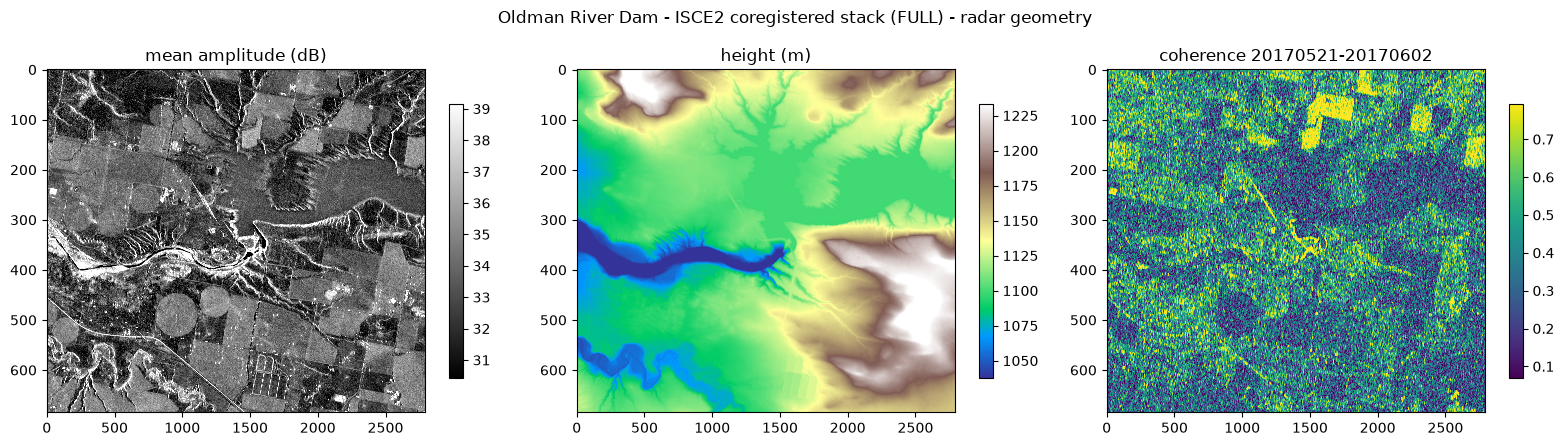

mean coherence: 0.4 | figure saved to /home/jovyan/oldman_isce2/stack_FULL/quicklook.png


In [34]:
import h5py, numpy as np, matplotlib.pyplot as plt
with h5py.File(OUT / 'slcStack.h5', 'r') as f, h5py.File(OUT / 'geometryRadar.h5', 'r') as g:
    dates = [d.decode() if isinstance(d, bytes) else str(d) for d in np.ravel(f['date'][:])]
    print('slcStack.h5      slc', f['slc'].shape, f['slc'].dtype, '| dates', dates[0], '...', dates[-1], f'({len(dates)})')
    print('                 bperp (m):', np.round(f['bperp'][:5], 1), '...')
    print('geometryRadar.h5', {k: g[k].shape for k in g.keys()})
    lat, lon = g['latitude'][:], g['longitude'][:]
    print(f'latitude {np.nanmin(lat):.3f} to {np.nanmax(lat):.3f}, longitude {np.nanmin(lon):.3f} to {np.nanmax(lon):.3f}')
    i0, i1 = dates.index(REF_DATE), min(dates.index(REF_DATE) + 1, len(dates) - 1)
    s0, s1 = f['slc'][i0], f['slc'][i1]
    amp = np.zeros(s0.shape, np.float32)
    for i in range(len(dates)):
        amp += np.abs(f['slc'][i]) ** 2
    amp_db = 10 * np.log10(amp / len(dates) + 1e-6)
    hgt = g['height'][:]

def boxcar(a, n=5):
    from scipy.ndimage import uniform_filter
    return uniform_filter(a.real, n) + 1j * uniform_filter(a.imag, n) if np.iscomplexobj(a) else uniform_filter(a, n)
ifg = s0 * np.conj(s1)
coh = np.abs(boxcar(ifg)) / np.sqrt(boxcar(np.abs(s0) ** 2) * boxcar(np.abs(s1) ** 2) + 1e-12)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, img, t, cm in zip(ax, [amp_db, hgt, coh], ['mean amplitude (dB)', 'height (m)', f'coherence {dates[i0]}-{dates[i1]}'],
                         ['gray', 'terrain', 'viridis']):
    v = np.nanpercentile(img, [2, 98])
    im = a.imshow(img, cmap=cm, vmin=v[0], vmax=v[1], aspect='auto', interpolation='nearest')
    a.set_title(t); plt.colorbar(im, ax=a, shrink=0.8)
plt.suptitle(f'Oldman River Dam - ISCE2 coregistered stack ({MODE}) - radar geometry')
plt.tight_layout(); plt.savefig(WORK / 'quicklook.png', dpi=150); plt.show()
print('mean coherence:', float(np.nanmean(coh)).__round__(2), '| figure saved to', WORK / 'quicklook.png')

## 12. Optional: free disk space after FULL
Once the `.h5` files are checked, the large intermediate folders can go:
- `coreg_secondarys`: coregistered bursts, about 0.6 GB per date
- `SLC`: the SAFE files, about 0.3 GB per date, only needed to process again

The merged full-resolution SLCs in `merged/SLC` are kept. **Nothing is deleted unless you set `DELETE = True`.**

In [35]:
DELETE = False
targets = [WORK / 'coreg_secondarys']
for t in targets:
    size = sum(p.stat().st_size for p in t.rglob('*') if p.is_file()) / 1e9 if t.exists() else 0
    print(f'{t}: {size:.1f} GB', '-> deleting' if DELETE and t.exists() else '')
    if DELETE and t.exists():
        shutil.rmtree(t)

/home/jovyan/oldman_isce2/stack_FULL/coreg_secondarys: 130.2 GB 


### Reading the files later in Python
```python
import h5py
f = h5py.File('slcStack.h5')          # f['slc'][i] = coregistered complex SLC of date f['date'][i]
g = h5py.File('geometryRadar.h5')     # height, latitude, longitude, incidenceAngle, azimuthAngle, shadowMask, slantRangeDistance
```
These files are the input of MiaplPy's phase-linking steps (`miaplpyApp.py ... --dostep phase_linking`), and they can be used directly for your own processing.